# AIDA 2156 Project Exercise 01 – Intake Volume Profile

**Question:** How many fictional onboarding requests arrive by task type and intake channel?

This notebook uses the synthetic `requests.csv` dataset created in AIDA 1141 Exercise 02 for the fictional Town of Pinecrest. It summarizes request volume and presents the counts in a labelled chart.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# The notebook reads the dataset directly from AIDA 1141 Exercise 02 (no copy is made)
DATA_PATH = Path("../../../AIDA-1141/project-labs/02-synthetic-request-records/data/requests.csv")
OUTPUT_DIR = Path("outputs")

# keep_default_na=False stops pandas turning the text "not_applicable" into missing;
# only truly empty cells are treated as missing
requests = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""], parse_dates=["submitted_at"])
print(f"Loaded {len(requests):,} rows from {DATA_PATH.name}")

Loaded 2,064 rows from requests.csv


## What one row represents

Each row represents one onboarding task, rather than one employee. The dataset contains 2,064 requests for 500 fictional employees, with 2–5 tasks per employee and an average of 4.13. Requests were submitted between January 21 and September 21, 2026.

In [2]:
print("Rows (tasks):", len(requests))
print("Columns:", requests.shape[1])
print("Unique employees:", requests["employee_id"].nunique())
print("Unique request IDs:", requests["request_id"].nunique())  # equals rows -> one row per task
print("Submitted from", requests["submitted_at"].min().date(), "to", requests["submitted_at"].max().date())

# How many tasks each employee has
print("\nTasks per employee:")
print(requests.groupby("employee_id").size().describe().round(2))

# Check the two columns this exercise depends on have no missing values
print("\nMissing values in the columns used:")
print(requests[["task_type", "intake_channel"]].isna().sum())

Rows (tasks): 2064
Columns: 20
Unique employees: 500
Unique request IDs: 2064
Submitted from 2026-01-21 to 2026-09-21

Tasks per employee:
count    500.00
mean       4.13
std        0.72
min        2.00
25%        4.00
50%        4.00
75%        5.00
max        5.00
dtype: float64

Missing values in the columns used:
task_type         0
intake_channel    0
dtype: int64


In [3]:
channel_order = ["web_form", "email", "phone"]
task_order = requests["task_type"].value_counts().index  # most to least common

# Counts and shares by task type
by_task = requests["task_type"].value_counts()
display(pd.DataFrame({"requests": by_task, "share_%": (by_task / len(requests) * 100).round(1)}))

# Counts and shares by intake channel
by_channel = requests["intake_channel"].value_counts().reindex(channel_order)
display(pd.DataFrame({"requests": by_channel, "share_%": (by_channel / len(requests) * 100).round(1)}))

# Task type x channel table with totals, saved for the README
counts = pd.crosstab(requests["task_type"], requests["intake_channel"], margins=True, margins_name="Total")
counts = counts.reindex(index=list(task_order) + ["Total"], columns=channel_order + ["Total"])
counts.to_csv(OUTPUT_DIR / "intake_counts.csv")
counts

,requests,share_%
task_type,,
payroll_setup,500,24.2
system_access,500,24.2
orientation_scheduling,426,20.6
workplace_access,322,15.6
equipment_setup,316,15.3


,requests,share_%
intake_channel,,
web_form,1096,53.1
email,661,32.0
phone,307,14.9


intake_channel,web_form,email,phone,Total
task_type,,,,
payroll_setup,363,98,39,500
system_access,268,164,68,500
orientation_scheduling,184,188,54,426
workplace_access,125,96,101,322
equipment_setup,156,115,45,316
Total,1096,661,307,2064


## How the counts were calculated

Each request was counted once by task type and once by intake channel using pandas `value_counts`, with each percentage calculated as the count divided by 2,064 and multiplied by 100. The task type × channel table was created using `pd.crosstab`, including row and column totals, and saved to `outputs/intake_counts.csv`. No rows were filtered or excluded, and neither column had missing values.

## What the counts show

Payroll setup and system access are the most common task types, with 500 requests each (24.2% each). Orientation scheduling accounts for 426 requests (20.6%), followed by workplace access with 322 (15.6%) and equipment setup with 316 (15.3%).

Web forms are the most common intake channel, with 1,096 requests (53.1%). Email accounts for 661 requests (32.0%), while phone accounts for 307 (14.9%).

Payroll requests mostly arrive through web forms, with 363 of 500 using this channel. Orientation requests have similar counts for web forms and email, at 184 and 188 respectively. Workplace access has the highest number of phone requests, at 101.

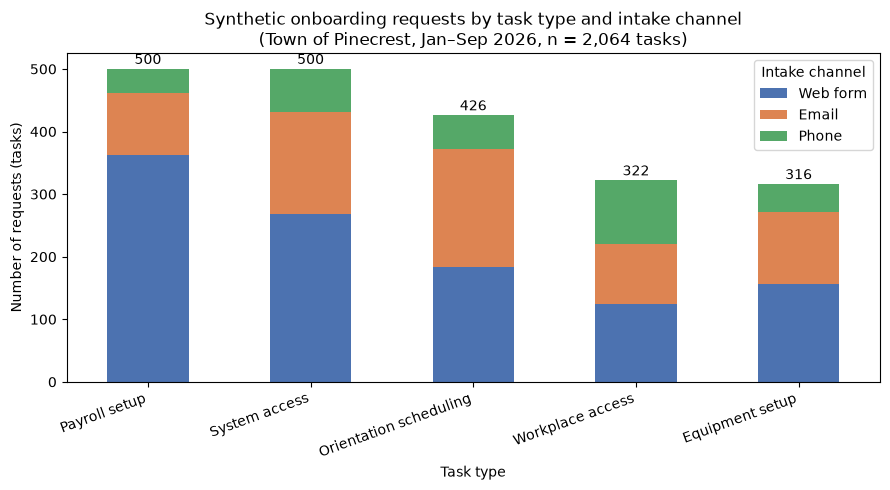

In [4]:
plot_data = counts.drop(index="Total", columns="Total")

ax = plot_data.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_title("Synthetic onboarding requests by task type and intake channel\n"
             f"(Town of Pinecrest, Jan–Sep 2026, n = {len(requests):,} tasks)")
ax.set_xlabel("Task type")
ax.set_ylabel("Number of requests (tasks)")
ax.set_xticklabels([t.replace("_", " ").capitalize() for t in plot_data.index], rotation=20, ha="right")
ax.legend(title="Intake channel", labels=["Web form", "Email", "Phone"])

# Total above each bar
for i, total in enumerate(plot_data.sum(axis=1)):
    ax.text(i, total + 8, str(total), ha="center")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "intake_volume_plot.png", dpi=150)
plt.show()

## What the plot shows

The stacked bar chart shows one bar per task type, with coloured segments representing the number of requests from each intake channel and the total labelled above each bar. Web forms account for the largest segment in most task types, while workplace access has the highest proportion of phone requests. The chart describes synthetic request volumes, so these patterns reflect the generator’s assumptions rather than real HR intake.

## Is the sample sufficient?

The dataset supports descriptive counts of task types and intake channels within this fictional workflow. Some combinations are smaller than others, including phone requests for payroll setup (39) and equipment setup (45). These smaller groups would need closer consideration before making statistical comparisons.

All records are synthetic, so the patterns reflect the generator’s assumptions. They do not establish how requests are distributed in a real HR department.